# Reinforcement Learning — Chapter 5: Monte Carlo Methods
A hands-on companion to Sutton & Barto, *Reinforcement Learning: An Introduction*, second edition. Original examples, organized by sections 5.1–5.9. Run cells in order. Requirements: `numpy`, `matplotlib`, Jupyter. No API keys or GPU.

**Learning goals:** estimate state and action values from episodes; distinguish first/every visit; implement exploring starts, on-policy and off-policy control; derive importance sampling and incremental updates; understand discounting-aware and per-decision estimators.

## 0. Environment and Chapter 4 benchmark
Our familiar gridworld is `A B / C GOAL`. Each move costs −1, boundaries self-loop, goal terminates, $\gamma=0.9$. All four actions are initially equally likely. The agent sees only `step` outputs, not the transition matrix. We use DP only as an independent benchmark.

$$v_\pi(s)=\mathbb E_\pi[G_t\mid S_t=s],\qquad G_t=\sum_{k=0}^{T-t-1}\gamma^k R_{t+k+1}.$$


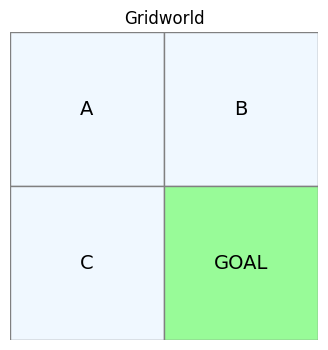

Random-policy DP benchmark: [-4.9689441  -3.85093168 -3.85093168  0.        ]


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
rng = np.random.default_rng(42)
gamma = .9
names = ['A','B','C','GOAL']
actions = ['↑','↓','←','→']
GOAL = 3
uniform = np.full((4,4), .25)

class Gridworld:
    _transitions = np.array([[0,2,0,1],[1,3,0,1],[0,2,2,3],[3,3,3,3]])
    def step(self,s,a):
        if s == GOAL: return GOAL, 0, True
        ns = int(self._transitions[s,a])
        return ns, -1, ns == GOAL

env = Gridworld()

def draw_grid(values=None, policy=None, title='Gridworld'):
    fig, ax = plt.subplots(figsize=(4,4))
    for s in range(4):
        r,c = divmod(s,2)
        ax.add_patch(Rectangle((c,1-r),1,1,facecolor='palegreen' if s==3 else 'aliceblue',edgecolor='gray'))
        txt = names[s]
        if values is not None: txt += f'\n{values[s]:.3f}'
        if policy is not None and s!=3: txt += '\n'+actions[int(policy[s])]
        ax.text(c+.5,1.5-r,txt,ha='center',va='center',fontsize=14)
    ax.set(xlim=(0,2),ylim=(0,2),aspect='equal',title=title); ax.axis('off'); plt.show()

draw_grid()
# Independent DP benchmark; never used in MC training.
P = np.array([[.5,.25,.25],[.25,.5,0],[.25,0,.5]])
V_exact = np.r_[np.linalg.solve(np.eye(3)-gamma*P,-np.ones(3)),0]
print('Random-policy DP benchmark:', V_exact)
assert np.allclose(V_exact,[-4.9689441,-3.85093168,-3.85093168,0])

## 5.1 Monte Carlo prediction
MC waits until termination, then computes observed returns backward: $G_t=R_{t+1}+\gamma G_{t+1}$, with $G_T=0$. Unlike DP, this recursion uses actual rewards, not an estimated successor-state value (no bootstrapping).

First-visit MC averages returns from the first chronological visit to each state per episode; every-visit MC uses all visits. Both converge under standard episodic sampling conditions. Do not confuse the first visit with the first state encountered in a **backward** loop.

Example: A → B → A → C → GOAL. Returns are −3.439, −2.71, −1.9, −1. First-visit A gets −3.439; every-visit A gets both −3.439 and −1.9.

In [2]:
def episode(policy, start=0, first_action=None, max_steps=10000):
    s = start; trajectory = []
    for t in range(max_steps):
        a = first_action if t==0 and first_action is not None else int(rng.choice(4,p=policy[s]))
        ns,r,done = env.step(s,a)
        trajectory.append((s,a,r,float(policy[s,a])))
        s = ns
        if done: return trajectory
    raise RuntimeError('Episode did not terminate; no truncated return used.')

def returns(ep):
    out=np.zeros(len(ep)); G=0.
    for t in reversed(range(len(ep))):
        G=ep[t][2]+gamma*G; out[t]=G
    return out

manual=[[(0,3,-1,.25),(1,1,-1,.25)],
        [(0,3,-1,.25),(1,2,-1,.25),(0,1,-1,.25),(2,3,-1,.25)],
        [(0,0,-1,.25),(0,1,-1,.25),(2,3,-1,.25)]]
for ep in manual:
    print([(names[s],actions[a],round(g,3)) for (s,a,r,p),g in zip(ep,returns(ep))])
assert np.allclose(returns(manual[1]),[-3.439,-2.71,-1.9,-1])

[('A', '→', np.float64(-1.9)), ('B', '↓', np.float64(-1.0))]
[('A', '→', np.float64(-3.439)), ('B', '←', np.float64(-2.71)), ('A', '↓', np.float64(-1.9)), ('C', '→', np.float64(-1.0))]
[('A', '↑', np.float64(-2.71)), ('A', '↓', np.float64(-1.9)), ('C', '→', np.float64(-1.0))]


First [-2.683 -1.855 -1.     0.   ] counts [3 2 2 0]
Every [-2.3698 -1.855  -1.      0.    ] counts [5 2 2 0]


First visit: [-4.96226213 -3.82746743 -3.83298051  0.        ] Every visit: [-4.96545596 -3.86621333 -3.83430354  0.        ]


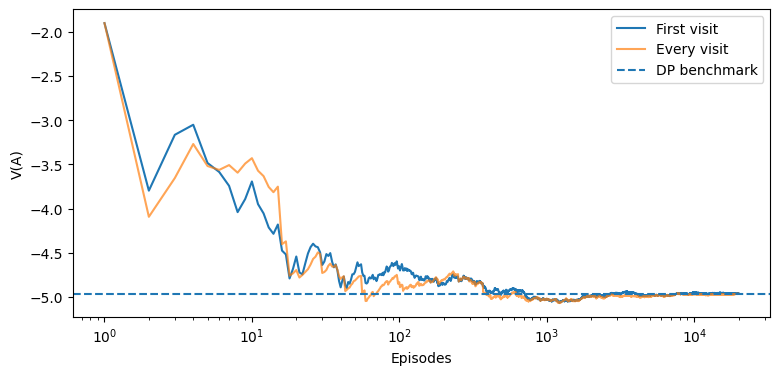

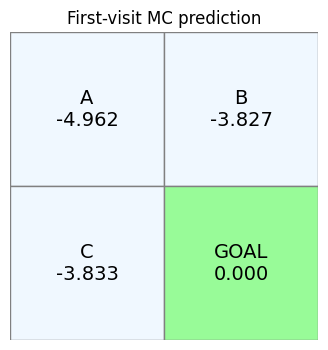

In [3]:
def predict(episodes, first=True, action_values=False):
    shape=(4,4) if action_values else (4,)
    V=np.zeros(shape); N=np.zeros(shape,int); history=[]
    for ep in episodes:
        seen=set()
        for (s,a,r,p),G in zip(ep,returns(ep)):
            key=(s,a) if action_values else s
            if first and key in seen: continue
            seen.add(key); N[key]+=1
            V[key]+=(G-V[key])/N[key]
        history.append(V.copy())
    return V,N,np.array(history)
for first in [True,False]:
    V,N,_=predict(manual,first)
    print('First' if first else 'Every', V, 'counts',N)
assert np.allclose(predict(manual)[0],[-2.683,-1.855,-1,0])
assert np.isclose(predict(manual,False)[0][0],-2.3698)
# Use identical episodes for fair comparison.
data=[episode(uniform) for _ in range(20000)]
Vf,Nf,Hf=predict(data); Ve,Ne,He=predict(data,False)
print('First visit:',Vf,'Every visit:',Ve)
assert np.max(abs(Vf-V_exact))<.12 and np.max(abs(Ve-V_exact))<.12
fig,ax=plt.subplots(figsize=(9,4))
ax.plot(np.arange(1,len(data)+1),Hf[:,0],label='First visit')
ax.plot(np.arange(1,len(data)+1),He[:,0],label='Every visit',alpha=.7)
ax.axhline(V_exact[0],ls='--',label='DP benchmark'); ax.set(xscale='log',xlabel='Episodes',ylabel='V(A)'); ax.legend(); plt.show()
draw_grid(Vf,title='First-visit MC prediction')

## 5.2 Action-value prediction
Without a model, $V(s)$ alone cannot tell us the consequences of an untried action. Estimate $q_\pi(s,a)=\mathbb E_\pi[G_t\mid S_t=s,A_t=a]$ directly by averaging returns from visits to each pair. Unvisited pairs have no evidence; zero is only initialization. For the manual episodes, $Q(A,\rightarrow)=(-1.9-3.439)/2=-2.6695$.

In [4]:
Qm,Nm,_=predict(manual,action_values=True)
print('Manual Q table (NaN = not observed):\n',np.where(Nm[:3]>0,Qm[:3],np.nan))
Qrand,Nrand,_=predict(data,action_values=True)
print('Random-policy Q estimates:\n',np.round(Qrand[:3],3))
assert np.isclose(Qm[0,3],-2.6695)
assert np.max(abs(np.sum(uniform[:3]*Qrand[:3],axis=1)-V_exact[:3]))<.15

Manual Q table (NaN = not observed):
 [[-2.71   -1.9        nan -2.6695]
 [    nan -1.     -2.71       nan]
 [    nan     nan     nan -1.    ]]
Random-policy Q estimates:
 [[-5.469 -4.45  -5.479 -4.445]
 [-4.5   -1.    -5.449 -4.46 ]
 [-5.467 -4.47  -4.436 -1.   ]]


## 5.3 MC control with exploring starts
Generalized policy iteration alternates estimation and greedification: $\pi(s)\in\arg\max_a Q(s,a)$. Exploring starts force a random starting state-action pair; later actions follow the current policy. This ensures coverage of starting pairs but does **not** by itself guarantee termination under arbitrary greedy policies. Our grid has self-loops, so a careless greedy initialization can get stuck.

For this demonstration we use a proper-policy starting Q table with a small preference for goal-reaching actions. To avoid hanging, the episode generator raises on excessive length rather than silently treating truncation as termination. With the chosen seed this example terminates. This initialization is a teaching choice, not an assumption of the general algorithm.

In [5]:
def greedy_policy(Q):
    p=np.zeros((4,4)); p[np.arange(4),np.argmax(Q,axis=1)]=1
    return p

def update_q(ep,Q,N):
    seen=set()
    for (s,a,r,p),G in zip(ep,returns(ep)):
        if (s,a) in seen: continue
        seen.add((s,a)); N[s,a]+=1
        Q[s,a]+=(G-Q[s,a])/N[s,a]

def mc_es(n=6000):
    # Pessimistic initial values for untried actions; a proper initial policy.
    Q=np.full((4,4),-10.); Q[3]=0
    Q[0,3]=-1.9; Q[1,1]=-1; Q[2,3]=-1
    N=np.zeros((4,4),int)
    for _ in range(n):
        s=int(rng.integers(3)); a=int(rng.integers(4))
        ep=episode(greedy_policy(Q),s,a)
        update_q(ep,Q,N)
    return Q,N
Qes,Nes=mc_es()
print('ES counts:\n',Nes[:3]); print('ES Q:\n',Qes[:3])
assert np.all(Nes[:3]>0)

ES counts:
 [[ 507  432  497 2556]
 [ 484 4049  519  502]
 [ 508  518  504 1951]]
ES Q:
 [[-2.71 -1.9  -2.71 -1.9 ]
 [-1.9  -1.   -2.71 -1.9 ]
 [-2.71 -1.9  -1.9  -1.  ]]


## 5.4 On-policy MC control without exploring starts
Use an $\epsilon$-soft policy to keep exploration. For four actions, the chosen greedy action has probability $1-\epsilon+\epsilon/4$, others $\epsilon/4$. At $\epsilon=.2$ these are .85 and .05. Fixed epsilon optimizes within the epsilon-soft setting, not necessarily the unrestricted optimal Q function. A GLIE schedule requires greediness in the limit **and** infinite exploration; simply decreasing epsilon is not sufficient in general.

We update Q after each episode and rebuild the epsilon-greedy policy. The average uses data from changing policies (GPI), unlike fixed-policy prediction.

Q: [[-2.963 -2.085 -2.946 -2.082]
 [-2.072 -1.    -2.98  -2.097]
 [-2.969 -2.141 -2.13  -1.   ]]
Behavior policy: [[0.05 0.05 0.05 0.85]
 [0.05 0.85 0.05 0.05]
 [0.05 0.05 0.05 0.85]]


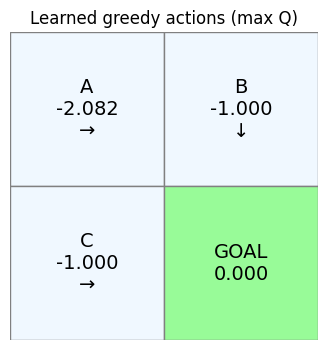

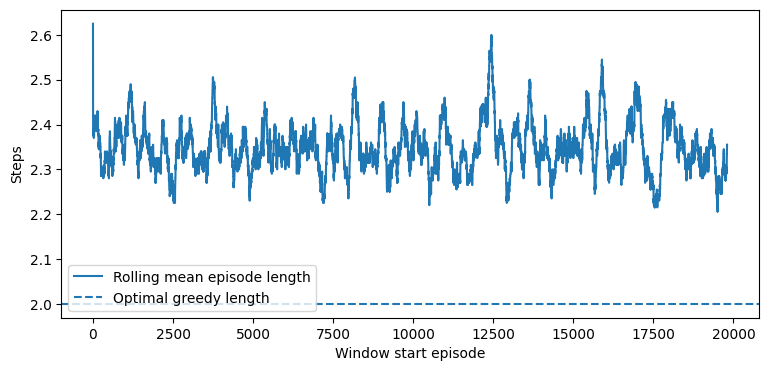

In [6]:
def epsilon_greedy(Q,eps):
    return (1-eps)*greedy_policy(Q)+eps/4

def mc_control(n=20000, eps=.2):
    Q=np.zeros((4,4)); N=np.zeros((4,4),int); p=uniform.copy()
    lengths=[]; rewards=[]
    for i in range(n):
        ep=episode(p); update_q(ep,Q,N)
        p=epsilon_greedy(Q,eps)
        lengths.append(len(ep)); rewards.append(returns(ep)[0])
    return Q,N,p,np.array(lengths),np.array(rewards)
Qon,Non,pon,lengths,rewards=mc_control()
print('Q:',np.round(Qon[:3],3)); print('Behavior policy:',pon[:3])
draw_grid(Qon.max(axis=1),Qon.argmax(axis=1),'Learned greedy actions (max Q)')
fig,ax=plt.subplots(figsize=(9,4)); window=200
ax.plot(np.convolve(lengths,np.ones(window)/window,mode='valid'),label='Rolling mean episode length')
ax.axhline(2,ls='--',label='Optimal greedy length'); ax.set(xlabel='Window start episode',ylabel='Steps'); ax.legend(); plt.show()
assert Qon.argmax(axis=1)[0] in [1,3] and Qon.argmax(axis=1)[1]==1 and Qon.argmax(axis=1)[2]==3

## 5.5 Off-policy prediction: importance sampling
Behavior $b$ produces data; target $\pi$ is evaluated. Coverage requires $b(a|s)>0$ whenever $\pi(a|s)>0$. Environment transition probabilities cancel from the trajectory likelihood ratio:
$$\rho_{t:T-1}=\prod_{k=t}^{T-1}\frac{\pi(A_k|S_k)}{b(A_k|S_k)}.$$
For state-value prediction include the action at time t. For action-value prediction conditional on $A_t=a$, start the ratio at $t+1$.

Our deterministic target chooses A→B→GOAL, C→GOAL. Under uniform behavior the matching two-step episode has weight 16; other trajectories from A get zero. Ordinary IS divides by sample count; weighted IS divides by sum of weights. Ordinary first-visit IS is unbiased under standard assumptions; weighted IS is generally finite-sample biased but consistent (when defined).

Weights: [16.  0.  0.] returns: [-1.9   -3.439 -2.71 ]
Ordinary: -10.133333333333333 Weighted: -1.9


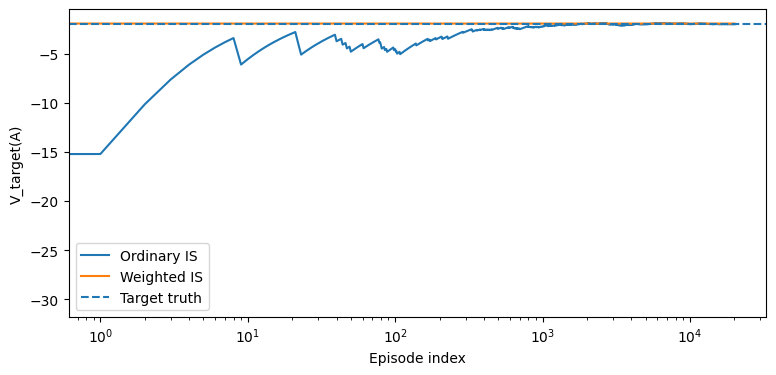

Final ordinary / weighted: -1.9729600000000482 -1.9000000000000465


In [7]:
target=np.zeros((4,4)); target[np.arange(4),[3,1,3,0]]=1

def ratio(ep,t=0):
    return np.prod([target[s,a]/p for s,a,r,p in ep[t:]])
w=np.array([ratio(ep) for ep in manual]); g=np.array([returns(ep)[0] for ep in manual])
print('Weights:',w,'returns:',g)
print('Ordinary:',np.mean(w*g),'Weighted:',np.dot(w,g)/w.sum())
assert np.array_equal(w,[16,0,0])
assert np.isclose(np.dot(w,g)/w.sum(),-1.9)
weights=np.array([ratio(ep) for ep in data]); gs=np.array([returns(ep)[0] for ep in data])
ordinary=np.cumsum(weights*gs)/np.arange(1,len(data)+1)
cs=np.cumsum(weights)
weighted=np.divide(np.cumsum(weights*gs),cs,out=np.full(len(cs),np.nan),where=cs>0)
fig,ax=plt.subplots(figsize=(9,4)); ax.plot(ordinary,label='Ordinary IS'); ax.plot(weighted,label='Weighted IS'); ax.axhline(-1.9,ls='--',label='Target truth'); ax.set(xscale='log',xlabel='Episode index',ylabel='V_target(A)'); ax.legend(); plt.show()
print('Final ordinary / weighted:',ordinary[-1],weighted[-1])

## 5.6 Incremental implementation
For the nth sample, $V\leftarrow V+(G-V)/n$. For weighted IS maintain $C\leftarrow C+W$, then $V\leftarrow V+(W/C)(G-V)$ when $C>0$. This avoids storing all samples. The update is an average, not a TD bootstrap.

In [8]:
v=0.
for i,G in enumerate(g,1):
    v+=(G-v)/i; print(i,v)
assert np.isclose(v,-2.683)
v=0.; C=0.
for W,G in zip(weights,gs):
    C+=W
    if C>0: v+=W/C*(G-v)
assert np.isclose(v,weighted[-1])
print('Incremental weighted estimate:',v)

1 -1.9
2 -2.6695
3 -2.6830000000000003
Incremental weighted estimate: -1.9


## 5.7 Off-policy MC control
Use a fixed uniform behavior policy and a greedy target. Process each episode backward, initialize $G=0,W=1$, update $C(s,a)$ and $Q(s,a)$ using W, then greedify. If the recorded action disagrees with the new target, break: all earlier suffix weights would be zero. Otherwise divide W by the **recorded behavior probability**. The current action is not included in the weight used for its own Q update.

In this negative-reward grid, zero initialization can keep unvisited actions greedier than observed terminal actions, causing the backward update to stop immediately. We demonstrate this failure, then initialize nonterminal Q to −10 (a lower bound on discounted returns here). This is an environment-specific teaching choice.

This is the every-visit weighted off-policy control algorithm. Long matching suffixes can produce extreme weights; in large problems use numerical safeguards and monitor effective sample size.

Zero initialization failure:
 [[ 0.  0.  0.  0.]
 [ 0. -1.  0.  0.]
 [ 0.  0.  0. -1.]]
Off-policy Q:
 [[-2.71 -1.9  -2.71 -1.9 ]
 [-1.9  -1.   -2.71 -1.9 ]
 [-2.71 -1.9  -1.9  -1.  ]]
Exact Q*:
 [[-2.71 -1.9  -2.71 -1.9 ]
 [-1.9  -1.   -2.71 -1.9 ]
 [-2.71 -1.9  -1.9  -1.  ]]


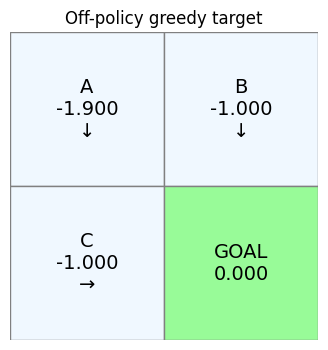

In [9]:
def off_control(episodes, initial=-10.):
    Q=np.full((4,4),initial); Q[3]=0; C=np.zeros((4,4)); pi=np.argmax(Q,axis=1)
    for ep in episodes:
        G=0.; W=1.
        for s,a,r,bprob in reversed(ep):
            G=r+gamma*G
            C[s,a]+=W; Q[s,a]+=W/C[s,a]*(G-Q[s,a])
            pi[s]=np.argmax(Q[s])
            if a!=pi[s]: break
            W/=bprob
    return Q,pi,C
Qzero,pizero,Czero=off_control(data,0.)
print("Zero initialization failure:\n", Qzero[:3])
Qoff,pioff,Coff=off_control(data)
Vstar=np.array([-1.9,-1,-1,0])
# Independent benchmark for all actions, not used for learning.
Qstar=np.zeros((4,4))
for s in range(3):
    for a in range(4):
        ns,r,_=env.step(s,a); Qstar[s,a]=r+gamma*Vstar[ns]
print('Off-policy Q:\n',Qoff[:3]); print('Exact Q*:\n',Qstar[:3])
assert np.allclose(Qoff,Qstar,atol=.03)
assert np.allclose(Qes,Qstar,atol=1e-8)
draw_grid(Qoff.max(axis=1),pioff,'Off-policy greedy target')

## 5.8 Importance sampling on truncated returns
Discounting can be interpreted as a geometric mixture of undiscounted partial returns. Here “truncated” means a mathematical partial return, not an episode cut off by a simulator time limit.

For horizon $H=T-t$, let $\bar G_{t:h}=\sum_{k=t}^{t+h-1}R_{k+1}$ for $1\le h\le H$. Then
$$G_t=(1-\gamma)\sum_{h=1}^{H-1}\gamma^{h-1}\bar G_{t:h}+\gamma^{H-1}\bar G_{t:H}.$$
Each partial return can be importance weighted only through its own horizon. Ordinary discounting-aware IS replaces each partial return above with $\rho_{t:t+h-1}\bar G_{t:h}$. Weighted discounting-aware IS divides the sum of weighted, discounted partial returns by the corresponding sum of discounted importance weights across all episodes. This can reduce the influence of irrelevant late actions; variance reduction is not universally guaranteed.

In [10]:
def truncated_terms(ep):
    H=len(ep); coeff=(1-gamma)*gamma**np.arange(H); coeff[-1]=gamma**(H-1)
    partial=np.cumsum([r for s,a,r,p in ep])
    prefix=np.cumprod([target[s,a]/p for s,a,r,p in ep])
    assert np.isclose(coeff@partial,returns(ep)[0])
    return np.dot(coeff*prefix,partial),np.dot(coeff,prefix)
terms=np.array([truncated_terms(ep) for ep in data])
print('Ordinary discounting-aware:',terms[:,0].mean())
print('Weighted discounting-aware:',terms[:,0].sum()/terms[:,1].sum())

Ordinary discounting-aware: -1.9701400000000002
Weighted discounting-aware: -1.9024508005175846


## 5.9 Per-decision importance sampling
Instead of weighting the entire return by the full trajectory ratio, weight each reward using only actions that precede it:
$$\widetilde G_t=\sum_{k=t}^{T-1}\gamma^{k-t}\rho_{t:k}R_{k+1}.$$
For the matching A→B→GOAL episode, full IS gives $16(-1.9)=-30.4$, whereas per-decision IS gives $4(-1)+.9(16)(-1)=-18.4$. Both are sample contributions, not final value estimates. Their expectations agree under appropriate coverage and integrability assumptions.

Full trajectory IS: -1.9729600000000482 Per-decision IS: -1.9447599999999998


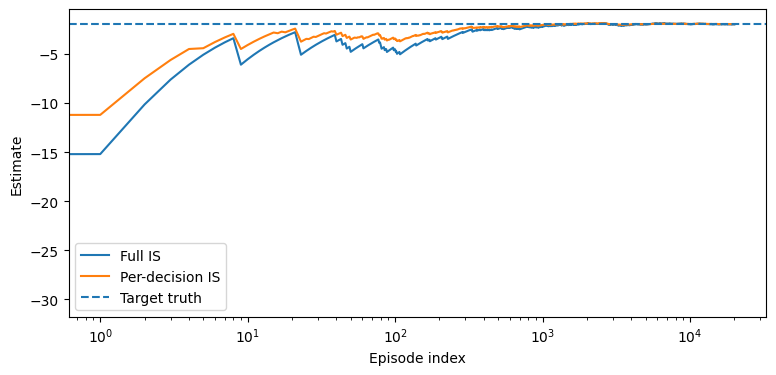

In [11]:
def per_decision(ep):
    prefix=1.; G=0.
    for t,(s,a,r,p) in enumerate(ep):
        prefix*=target[s,a]/p; G+=gamma**t*prefix*r
    return G
assert np.isclose(per_decision(manual[0]),-18.4)
pd=np.array([per_decision(ep) for ep in data])
print('Full trajectory IS:',ordinary[-1], 'Per-decision IS:',pd.mean())
fig,ax=plt.subplots(figsize=(9,4)); ax.plot(ordinary,label='Full IS'); ax.plot(np.cumsum(pd)/np.arange(1,len(pd)+1),label='Per-decision IS'); ax.axhline(-1.9,ls='--',label='Target truth'); ax.set(xscale='log',xlabel='Episode index',ylabel='Estimate'); ax.legend(); plt.show()

## 6. Exercises (with answers below)
1. For A→A→B→GOAL compute every return and first/every-visit V(A).
2. Why is a never-observed Q=0 not evidence that the action is better than Q=−1?
3. Change epsilon to .4. Compare training episode lengths and greedy policy.
4. For A→B→A→C→GOAL under uniform behavior, compute full and per-decision importance contributions for the deterministic target.
5. Agentic RAG: retrieve (−1), rerank (−.5), grounded answer (+10). Calculate the return and explain how to estimate Q(retrieval state, rerank) without a transition model.

### Solutions
1. Returns −2.71, −1.9, −1. First −2.71; every (−2.71−1.9)/2=−2.305.
2. Zero is initialization, not an observation. Explore before drawing conclusions.
3. Higher epsilon increases random actions; expected training paths typically lengthen even if the greedy policy remains optimal in this tiny grid. Compare with repeated seeds.
4. Full ratio zero because B→A violates target; per-decision contribution −4 because only the first reward has nonzero prefix weight.
5. Initial return −1−.45+8.1=6.65. Return from rerank is −.5+.9(10)=8.5. Average returns from visits to that state-action pair over logged episodes. In a real system use expert-validated rewards, adequate coverage, and logged behavior probabilities for off-policy estimation. Numbers are illustrative.

## Final comparison
| Method | Target | Model required? | Bootstrap? |
|---|---|---|---|
| DP | expected one-step backup | Yes | Yes |
| MC | observed complete return | No | No |
| TD (Chapter 6) | sampled reward + discounted estimated next value | No | Yes |

The central lesson: MC replaces model-based expectations with averages of actual sampled returns. Control adds policy improvement; off-policy learning corrects for the data-generating policy.